# Filtros espaciales pasabajos

**Procesamiento de Imágenes — Universidad Diego Portales**

Este cuaderno cubre el filtrado espacial *lineal* pasabajos (suavizado) y lo
compara con dos filtros *no lineales* de uso frecuente.


## 1. Preparación

Se trabaja con las imágenes del curso. Ajusta `DIR_IMG` a la carpeta donde las
tengas: el cuaderno espera al menos `gato.jpg` y `loros.png`.

In [1]:
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy :", np.__version__)

# Carpeta con las imágenes del curso
DIR_IMG = Path("imagenes")

# Tamaño por defecto de las figuras
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"

OpenCV: 5.0.0
NumPy : 2.5.3


In [2]:
# Verificación rápida de que las imágenes están donde corresponde
if not DIR_IMG.exists():
    raise FileNotFoundError(
        f"No existe la carpeta {DIR_IMG.resolve()}. "
        "Ajusta DIR_IMG a la ruta de tus imágenes."
    )

print("Archivos disponibles en", DIR_IMG.resolve())
for archivo in sorted(DIR_IMG.iterdir()):
    print("  -", archivo.name)

Archivos disponibles en D:\Documents\GitHub\Procesamiento-de-Imagenes-2026-2\Clases\clase 07\imagenes
  - __MACOSX
  - imagenes


### Utilidad para mostrar imágenes

Todas las visualizaciones del cuaderno usan la misma función. Dos detalles
importantes:

- `vmin=0, vmax=255` fija la escala de grises. Sin eso, `imshow` reescala cada
  imagen a su propio rango y dos imágenes con brillos distintos se ven iguales.
- OpenCV entrega las imágenes a color en orden **BGR** y matplotlib las espera
  en **RGB**; la función hace la conversión cuando detecta tres canales.

In [3]:
def mostrar(imagenes, titulos=None, cols=None, escala=3.2, ejes=False):
    """Muestra una o varias imágenes en una grilla.

    imagenes : imagen o lista de imágenes (uint8, en gris o BGR)
    titulos  : título o lista de títulos
    cols     : número de columnas (por defecto, todas en una fila)
    """
    if isinstance(imagenes, np.ndarray):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    if isinstance(titulos, str):
        titulos = [titulos]

    n = len(imagenes)
    cols = cols or n
    filas = int(np.ceil(n / cols))

    fig, axs = plt.subplots(filas, cols,
                            figsize=(escala * cols, escala * filas * 1.05))
    axs = np.atleast_1d(axs).ravel()

    for ax, img, titulo in zip(axs, imagenes, titulos):
        if img.ndim == 3:                      # color: BGR -> RGB
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:                                  # gris: escala fija 0-255
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(titulo, fontsize=10)
        if not ejes:
            ax.axis("off")

    for ax in axs[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [4]:
import cv2
import numpy as np
from skimage import data

# skimage entrega RGB; OpenCV trabaja en BGR
chelsea_rgb = data.chelsea()                                   # (300, 451, 3) uint8
img = cv2.cvtColor(chelsea_rgb, cv2.COLOR_RGB2BGR)
img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5)  # (150, 226, 3) uint8

Dimensiones : (150, 226, 3)
Tipo        : uint8
Rango       : 1 - 210


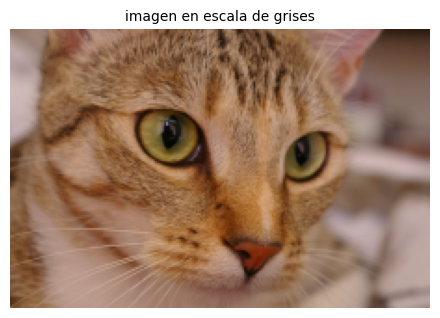

In [5]:
# Imagen de trabajo, 
#img = cv2.imread(str(DIR_IMG / "loros.png"))

if img is None:
    raise FileNotFoundError("cv2.imread devolvió None: revisa el nombre y la ruta.")

print("Dimensiones :", img.shape)
print("Tipo        :", img.dtype)
print("Rango       :", img.min(), "-", img.max())

mostrar(img, "imagen en escala de grises", escala=4.5)

## 2. Teoría: vecindad, máscara y filtrado lineal

Un **filtro espacial** calcula cada píxel de salida a partir de una *vecindad*
del píxel de entrada. Cuando esa combinación es una suma ponderada, el filtro
es **lineal** y los pesos forman la **máscara** o **kernel** $h$.

Para un kernel de $K \times K$ centrado en el origen ($i, j = -P \ldots P$, con
$P = (K-1)/2$), la **convolución** es

$$g(m,n) \;=\; \sum_{i=-P}^{P} \sum_{j=-P}^{P} h(i,j)\, f(m-i,\, n-j)$$

y la **correlación cruzada** es la misma expresión *sin* invertir el kernel:

$$g(m,n) \;=\; \sum_{i=-P}^{P} \sum_{j=-P}^{P} h(i,j)\, f(m+i,\, n+j)$$

La convolución rota el kernel 180°; la correlación no. Para todos los kernels
de este cuaderno la diferencia es nula, porque son simétricos, pero el detalle
importa.

### ¿Por qué "pasabajos"?

Los bordes, el ruido y la textura fina son **variaciones bruscas** de
intensidad, es decir, componentes de **alta frecuencia**. Un kernel cuyos pesos
son todos positivos y suman 1 promedia la vecindad: atenúa esas variaciones y
deja pasar las zonas de intensidad lentamente variable. De ahí el nombre.

Dos consecuencias prácticas:

- **Suavizar y difuminar bordes son el mismo fenómeno.** No se puede eliminar
  ruido con un filtro lineal sin perder algo de definición. Los filtros no
  lineales de la §8 existen justamente para atacar ese compromiso.
- **La suma de los pesos debe ser 1** para conservar el brillo medio. Si suma
  más de 1 la imagen se aclara (y satura en 255); si suma menos, se oscurece.

## 3. El kernel promedio (*box filter*)

El filtro pasabajos más simple: todos los pesos iguales, normalizados para que
sumen 1. Para $3 \times 3$:

$$h = \frac{1}{9}\begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

Cada píxel de salida es el promedio aritmético de su vecindad de $3 \times 3$.

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Suma de los pesos: 1.0


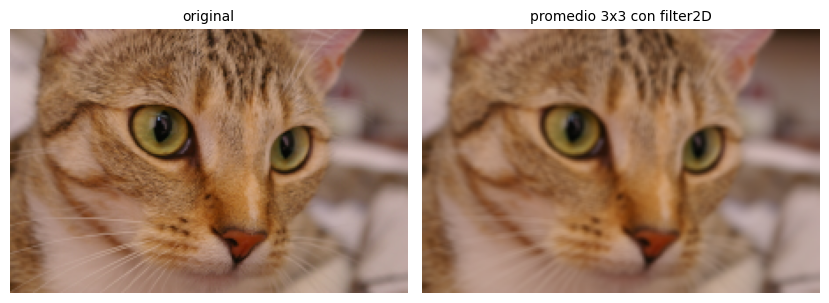

In [6]:
# Construcción explícita del kernel
K = 3
kernel_promedio = np.ones((K, K), dtype=np.float32) / (K * K)

print(kernel_promedio)
print("Suma de los pesos:", kernel_promedio.sum())

# Aplicación con filter2D
# ddepth=-1 -> la salida tiene la misma profundidad que la entrada (uint8)
suave = cv2.filter2D(img, ddepth=-1, kernel=kernel_promedio)

mostrar([img, suave],
        ["original", f"promedio {K}x{K} con filter2D"],
        escala=4.2)

### Las tres formas de hacer lo mismo

OpenCV ofrece atajos para el kernel promedio. Con `normalize=True`,
`boxFilter` es exactamente `blur`, y ambos coinciden con `filter2D` sobre el
kernel construido a mano.

In [7]:
via_filter2d = cv2.filter2D(img, -1, kernel_promedio)
via_blur     = cv2.blur(img, (K, K))
via_box      = cv2.boxFilter(img, -1, (K, K), normalize=True)

print("filter2D == blur      :", np.array_equal(via_filter2d, via_blur))
print("blur     == boxFilter :", np.array_equal(via_blur, via_box))

filter2D == blur      : True
blur     == boxFilter : True


### Qué pasa si el kernel no está normalizado

Es el error más frecuente al construir kernels a mano. Con pesos que suman 9,
cada píxel se multiplica por 9 y casi toda la imagen se va a 255: OpenCV
**satura** en lugar de dar la vuelta como haría NumPy con `uint8`.

Media original : 115.5
Media filtrada : 253.4
% de píxeles en 255: 98.1


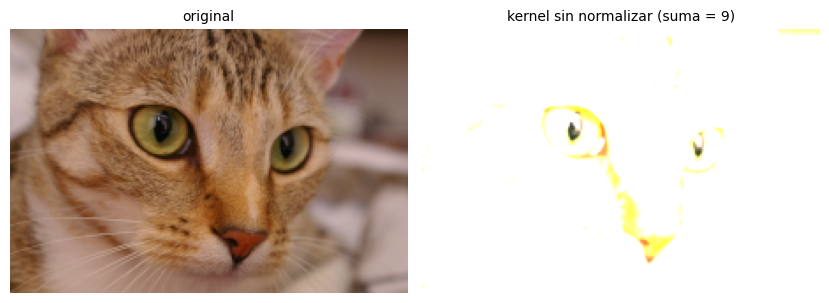

In [8]:
kernel_sin_normalizar = np.ones((3, 3), dtype=np.float32)   # suma = 9

mal = cv2.filter2D(img, -1, kernel_sin_normalizar)

print("Media original :", img.mean().round(1))
print("Media filtrada :", mal.mean().round(1))
print("% de píxeles en 255:", round(100 * (mal == 255).mean(), 1))

mostrar([img, mal], ["original", "kernel sin normalizar (suma = 9)"], escala=4.2)

El kernel usado desplaza la imagen un píxel: la correlación la mueve en un
sentido y la convolución en el opuesto. Ese es exactamente el efecto del giro
de 180°.

Con un kernel simétrico la distinción desaparece:

## 4. Efecto del tamaño del kernel

El tamaño del kernel controla cuánta vecindad se promedia. Es el parámetro que
más impacto visual tiene: al crecer, el suavizado aumenta y la definición cae.

Fíjate en dos cosas al aumentar el tamaño:

- la textura fina desaparece antes que las estructuras grandes;
- con kernels grandes aparecen **artefactos en bloque**, característicos del
  filtro promedio (la §6 muestra por qué el gaussiano no los produce).

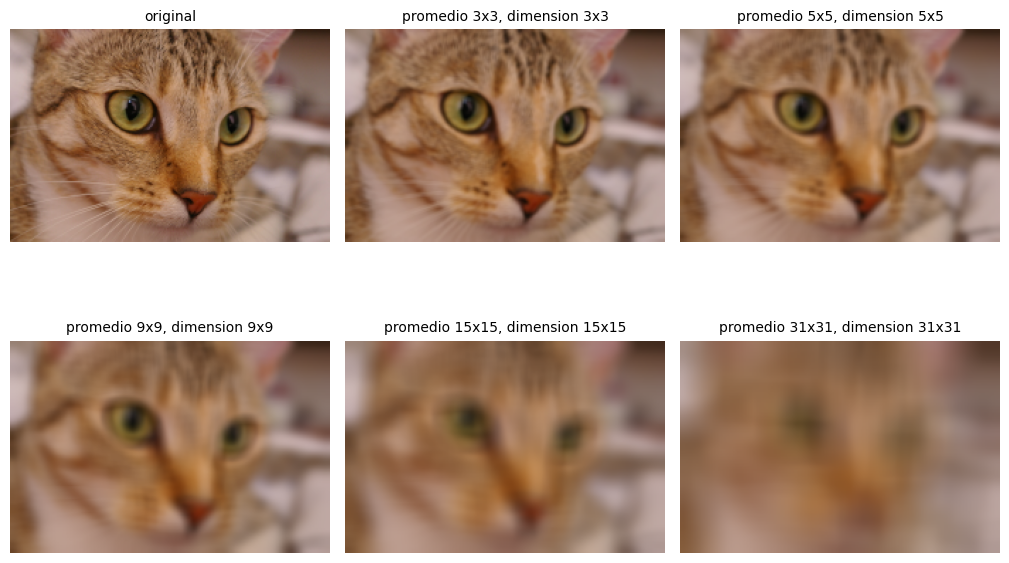

In [9]:
tamanos = [3, 5, 9, 15, 31]

resultados = [img]
titulos = ["original"]

for k in tamanos:
    resultados.append(cv2.blur(img, (k, k)))
    titulos.append(f"promedio {k}x{k}, dimension {k}x{k}")

mostrar(resultados, titulos, cols=3, escala=3.4)

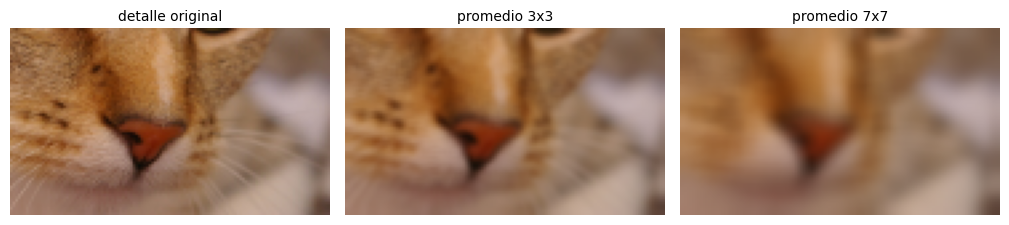

In [10]:
# Detalle ampliado: el mismo recorte con tres tamaños de kernel
y0, x0, lado = 80, 80, 120
recorte = img[y0:y0 + lado, x0:x0 + lado]

mostrar([recorte,
         cv2.blur(recorte, (3, 3)),
         cv2.blur(recorte, (7, 7))],
        ["detalle original", "promedio 3x3", "promedio 7x7"],
        escala=3.4)

## 5. Manejo de bordes

En los píxeles del borde la vecindad se sale de la imagen. OpenCV, a diferencia
del modo `valid`, **siempre entrega una salida del mismo tamaño que la
entrada**: rellena lo que falta según `borderType`.

| Constante | Qué hace con `abcdefgh` |
|---|---|
| `BORDER_CONSTANT` | `0000` \| `abcdefgh` \| `0000` |
| `BORDER_REPLICATE` | `aaaa` \| `abcdefgh` \| `hhhh` |
| `BORDER_REFLECT` | `dcba` \| `abcdefgh` \| `hgfe` |
| `BORDER_REFLECT_101` | `edcb` \| `abcdefgh` \| `gfed` (por defecto) |
| `BORDER_WRAP` | `efgh` \| `abcdefgh` \| `abcd` |

`BORDER_REFLECT_101` es el valor por defecto y no repite el píxel del borde,
por eso suele ser la mejor opción. `BORDER_CONSTANT` con valor 0 introduce un
marco oscuro artificial: es el equivalente al *zero padding*.

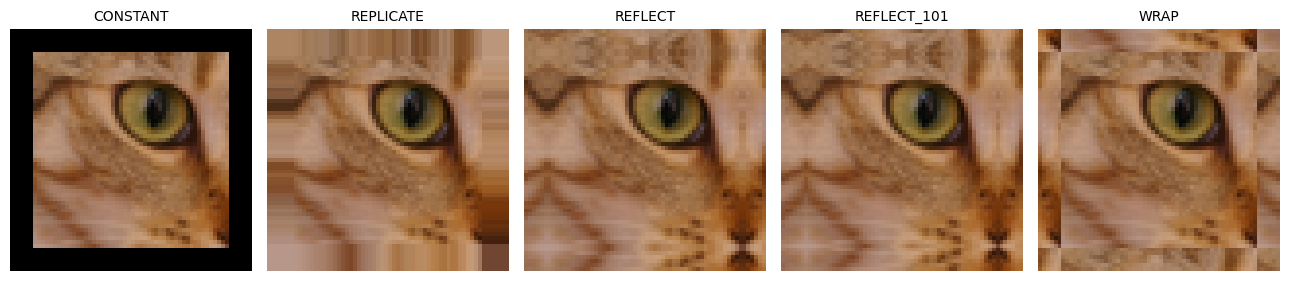

In [11]:
# El relleno hecho visible con copyMakeBorder sobre un recorte pequeño
pequeno = cv2.resize(img[30:100, 30:100], (50, 50), interpolation=cv2.INTER_AREA)
pequeno = cv2.resize(img[30:120, 30:120], (50, 50), interpolation=cv2.INTER_AREA)


b = 6  # ancho del relleno, exagerado para que se vea

tipos = [("CONSTANT",   cv2.BORDER_CONSTANT),
         ("REPLICATE",  cv2.BORDER_REPLICATE),
         ("REFLECT",    cv2.BORDER_REFLECT),
         ("REFLECT_101", cv2.BORDER_REFLECT_101),
         ("WRAP",       cv2.BORDER_WRAP)]

bordeadas, titulos = [], []
for nombre, tipo in tipos:
    bordeadas.append(cv2.copyMakeBorder(pequeno, b, b, b, b, tipo, value=0))
    titulos.append(nombre)

mostrar(bordeadas, titulos, cols=5, escala=2.6)

## 6. El kernel gaussiano

El promedio trata igual al píxel central que al de la esquina. El kernel
gaussiano pondera según la distancia:

$$h(i,j) \;=\; \frac{1}{2\pi\sigma^{2}} \, e^{-\frac{i^{2}+j^{2}}{2\sigma^{2}}}$$

Al ser suave y sin discontinuidades, no genera los artefactos en bloque del
promedio. Es el filtro pasabajos estándar en visión computacional.

En OpenCV, `getGaussianKernel(ksize, sigma)` entrega el kernel **1-D**
normalizado. Si `sigma <= 0`, lo calcula a partir del tamaño:

$$\sigma = 0.3\,\big((K-1)\cdot 0.5 - 1\big) + 0.8$$

In [12]:
K = 5
sigma = 1.0

g1d = cv2.getGaussianKernel(K, sigma)          # columna (K x 1)
g2d = g1d @ g1d.T                              # producto externo -> K x K

print("Kernel 1-D:\n", g1d.ravel().round(4))
print("\nKernel 2-D:\n", g2d.round(4))
print("\nSuma:", g2d.sum().round(6))

# Pesos relativos: cuánto pesa cada vecino respecto de la esquina
print("\nPesos relativos (esquina = 1):\n", (g2d / g2d.min()).round(1))

# Con ksize=3 el kernel gaussiano de OpenCV es exactamente el clásico 1/16
g3 = cv2.getGaussianKernel(3, 0)
print("\nKernel 1-D de 3 elementos:", g3.ravel())
print("Producto externo x 16:\n", (g3 @ g3.T * 16).round(3))

Kernel 1-D:
 [0.0545 0.2442 0.4026 0.2442 0.0545]

Kernel 2-D:
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]

Suma: 1.0

Pesos relativos (esquina = 1):
 [[ 1.   4.5  7.4  4.5  1. ]
 [ 4.5 20.1 33.1 20.1  4.5]
 [ 7.4 33.1 54.6 33.1  7.4]
 [ 4.5 20.1 33.1 20.1  4.5]
 [ 1.   4.5  7.4  4.5  1. ]]

Kernel 1-D de 3 elementos: [0.25 0.5  0.25]
Producto externo x 16:
 [[1. 2. 1.]
 [2. 4. 2.]
 [1. 2. 1.]]


In [13]:
# Sigma calculado automáticamente a partir del tamaño
for k in [3, 5, 9, 15, 31]:
    s = 0.3 * ((k - 1) * 0.5 - 1) + 0.8
    print(f"ksize = {k:2d}  ->  sigma automático = {s:.2f}")

ksize =  3  ->  sigma automático = 0.80
ksize =  5  ->  sigma automático = 1.10
ksize =  9  ->  sigma automático = 1.70
ksize = 15  ->  sigma automático = 2.60
ksize = 31  ->  sigma automático = 5.00


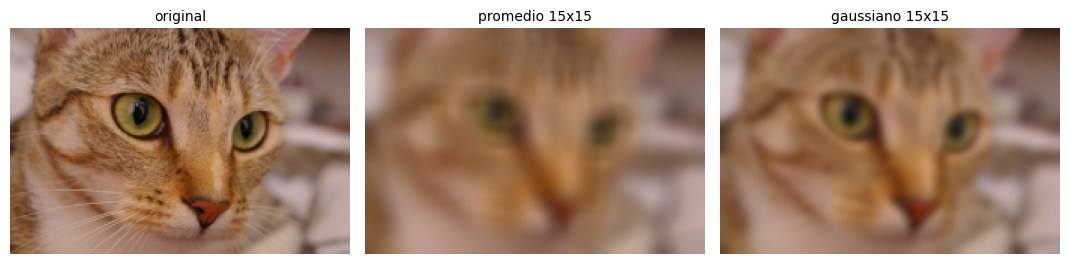

In [14]:
# Aplicación: GaussianBlur
k = 15
gauss_9 = cv2.GaussianBlur(img, (k, k), sigmaX=0)   # sigma automático
prom_9  = cv2.blur(img, (k, k))

mostrar([img, prom_9, gauss_9],
        ["original", f"promedio {k}x{k}", f"gaussiano {k}x{k}"],
        escala=3.6)

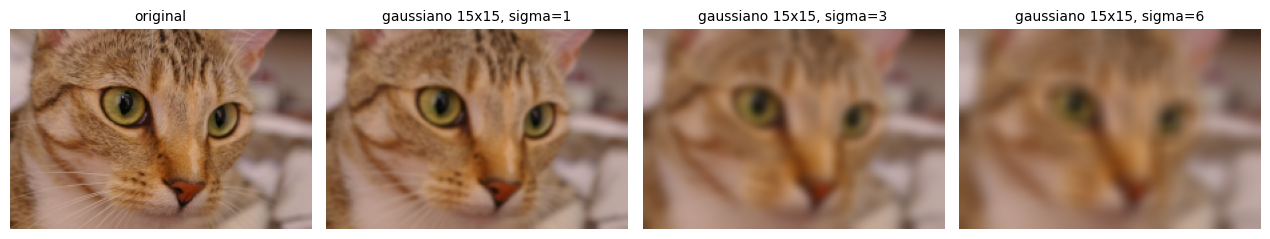

In [15]:
# Efecto de sigma con el tamaño fijo
k = 15
salidas = [img] + [cv2.GaussianBlur(img, (k, k), s) for s in [1, 3, 6]]
titulos = ["original"] + [f"gaussiano {k}x{k}, sigma={s}" for s in [1, 3, 6]]

mostrar(salidas, titulos, cols=4, escala=3.2)

## 7. Otros kernels pasabajos conocidos

Además del promedio y el gaussiano, aparecen con frecuencia:

- **Promedio ponderado** $\frac{1}{10}\begin{bmatrix}1&1&1\\1&2&1\\1&1&1\end{bmatrix}$:
  da el doble de peso al centro, suaviza algo menos.
- **Gaussiano entero**
  $\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$: es exactamente
  el kernel que devuelve `getGaussianKernel(3, 0)`, escrito en aritmética
  entera. Muy usado en hardware y en pirámides de imagen.
- **Cónico / piramidal**: pesos que decaen linealmente con la distancia.
- **Circular (disco)**: promedio dentro de un círculo; modela el desenfoque
  óptico de una lente, así que es el más realista para simular *out of focus*.

Todos se construyen a mano y se aplican con `filter2D`.

In [16]:
def kernel_disco(radio):
    """Kernel circular normalizado (promedio dentro de un disco)."""
    lado = 2 * radio + 1
    y, x = np.ogrid[-radio:radio + 1, -radio:radio + 1]
    k = (x**2 + y**2 <= radio**2).astype(np.float32)
    return k / k.sum()


def kernel_conico(radio):
    """Kernel cónico: los pesos decaen linealmente con la distancia."""
    y, x = np.ogrid[-radio:radio + 1, -radio:radio + 1]
    d = np.sqrt(x**2 + y**2)
    k = np.clip(radio + 1 - d, 0, None).astype(np.float32)
    return k / k.sum()


kernels = {
    "promedio 3x3":      np.ones((3, 3), np.float32) / 9,
    "ponderado 1/10":    np.array([[1, 1, 1],
                                   [1, 2, 1],
                                   [1, 1, 1]], np.float32) / 10,
    "gaussiano 1/16":    np.array([[1, 2, 1],
                                   [2, 4, 2],
                                   [1, 2, 1]], np.float32) / 16,
    "cónico r=4":        kernel_conico(4),
    "disco r=4":         kernel_disco(4),
}

for nombre, k in kernels.items():
    print(f"{nombre:18s} tamaño {k.shape}  suma {k.sum():.3f}")

promedio 3x3       tamaño (3, 3)  suma 1.000
ponderado 1/10     tamaño (3, 3)  suma 1.000
gaussiano 1/16     tamaño (3, 3)  suma 1.000
cónico r=4         tamaño (9, 9)  suma 1.000
disco r=4          tamaño (9, 9)  suma 1.000


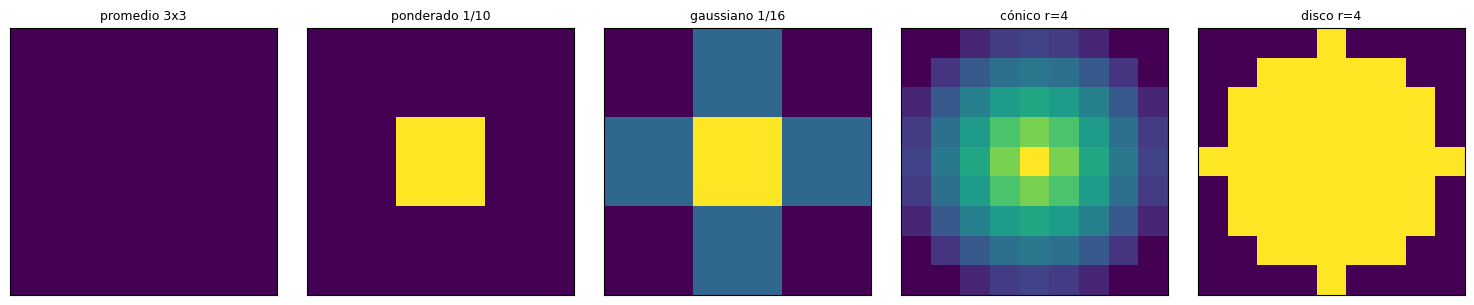

In [17]:
# Cómo se ven los kernels
fig, axs = plt.subplots(1, len(kernels), figsize=(3 * len(kernels), 3))
for ax, (nombre, k) in zip(axs, kernels.items()):
    ax.imshow(k, cmap="viridis")
    ax.set_title(nombre, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

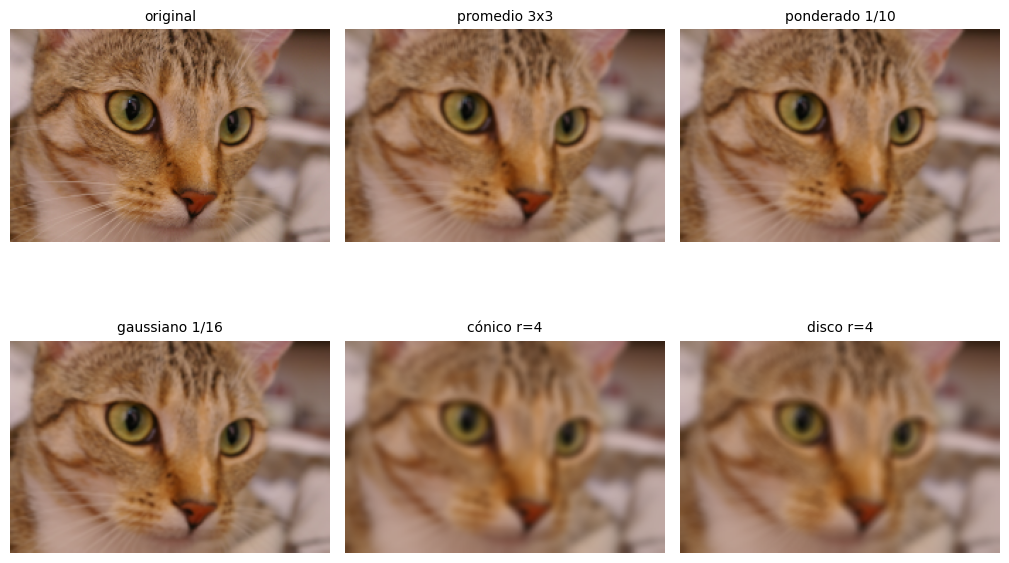

In [18]:
# Y cómo actúan sobre la imagen
salidas = [img] + [cv2.filter2D(img, -1, k) for k in kernels.values()]
titulos = ["original"] + list(kernels.keys())

mostrar(salidas, titulos, cols=3, escala=3.4)

## 8. Filtros no lineales: mediana y bilateral

Los dos siguientes **no son convoluciones**: no existe un kernel de pesos que
los represente, porque la operación sobre la vecindad no es una suma ponderada.

- **Mediana** (`cv2.medianBlur`): reemplaza el píxel por la mediana de su
  vecindad. Un valor extremo aislado —un píxel de ruido sal y pimienta— no
  arrastra la mediana, mientras que sí arrastra el promedio. Además preserva
  los bordes mucho mejor, porque la mediana de una vecindad a caballo entre dos
  regiones sigue siendo un valor de alguna de las dos, no un valor intermedio
  inventado.
- **Bilateral** (`cv2.bilateralFilter`): un gaussiano en el que cada vecino
  pesa según **dos** distancias, la espacial y la de intensidad. Los píxeles al
  otro lado de un borde tienen intensidad muy distinta, pesan poco y casi no
  participan del promedio: suaviza dentro de las regiones y respeta los bordes.
  Es bastante más lento.

### Primero, ensuciamos la imagen para simula ruido

Dos tipos de ruido con orígenes distintos: el gaussiano modela el ruido del
sensor y afecta a todos los píxeles; el sal y pimienta modela errores de
transmisión o píxeles defectuosos, y afecta a unos pocos con valores extremos.

Nota sobre tipos: la suma se hace en `float`. Si se sumara directamente sobre
`uint8`, NumPy daría la vuelta (255 + 1 = 0) en vez de saturar.

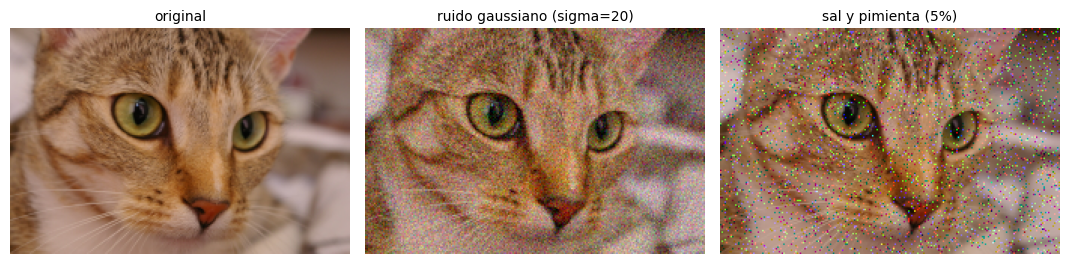

In [19]:
chelsea_rgb = data.chelsea()
img = cv2.cvtColor(chelsea_rgb, cv2.COLOR_RGB2BGR)
img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5)  # (150, 226, 3) uint8
#img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # escala de grises

rng = np.random.default_rng(0)

def ruido_gaussiano(imagen, sigma=20):
    ruido = rng.normal(0, sigma, imagen.shape)
    return np.clip(imagen.astype(np.float64) + ruido, 0, 255).astype(np.uint8)


def ruido_sal_pimienta(imagen, proporcion=0.05):
    salida = imagen.copy()
    mascara = rng.random(imagen.shape)
    salida[mascara < proporcion / 2] = 0        # pimienta
    salida[mascara > 1 - proporcion / 2] = 255  # sal
    return salida


img_gauss = ruido_gaussiano(img, sigma=20)
img_sp = ruido_sal_pimienta(img, proporcion=0.05)

mostrar([img, img_gauss, img_sp],
        ["original", "ruido gaussiano (sigma=20)", "sal y pimienta (5%)"],
        escala=3.6)

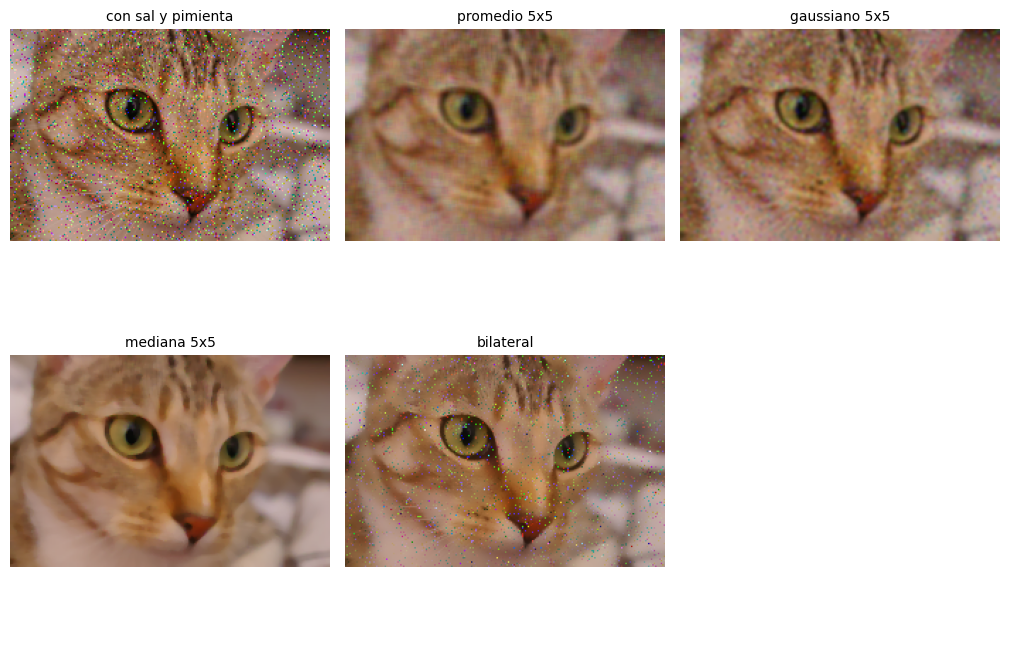

In [20]:
# Los cuatro filtros frente al ruido sal y pimienta
k = 5

comparacion = [
    img_sp,
    cv2.blur(img_sp, (k, k)),
    cv2.GaussianBlur(img_sp, (k, k), 0),
    cv2.medianBlur(img_sp, k),
    cv2.bilateralFilter(img_sp, d=9, sigmaColor=75, sigmaSpace=75),
]
titulos = ["con sal y pimienta", f"promedio {k}x{k}", f"gaussiano {k}x{k}",
           f"mediana {k}x{k}", "bilateral"]

mostrar(comparacion, titulos, cols=3, escala=3.4)

La mediana elimina el ruido sal y pimienta casi por completo; el promedio y el
gaussiano solo lo reparten entre los vecinos, dejando manchas grises. Es la
diferencia entre *quitar* el valor extremo y *promediarlo*.

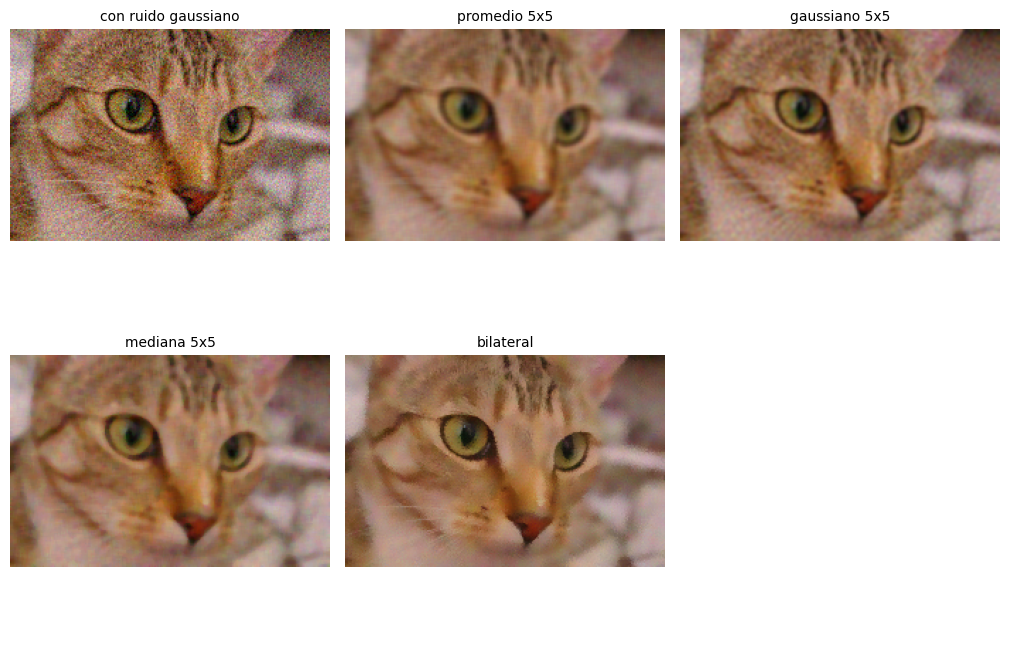

In [21]:
# Frente al ruido gaussiano el panorama cambia
comparacion = [
    img_gauss,
    cv2.blur(img_gauss, (5, 5)),
    cv2.GaussianBlur(img_gauss, (5, 5), 0),
    cv2.medianBlur(img_gauss, 5),
    cv2.bilateralFilter(img_gauss, d=9, sigmaColor=75, sigmaSpace=75),
]
titulos = ["con ruido gaussiano", "promedio 5x5", "gaussiano 5x5",
           "mediana 5x5", "bilateral"]

mostrar(comparacion, titulos, cols=3, escala=3.4)

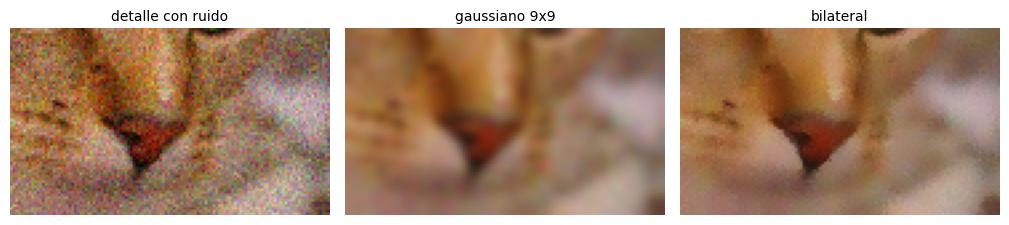

In [22]:
# Preservación de bordes: detalle ampliado, mismo recorte
y0, x0, lado = 80, 80, 120
r = img_gauss[y0:y0 + lado, x0:x0 + lado]

mostrar([r,
         cv2.GaussianBlur(r, (9, 9), 0),
         cv2.bilateralFilter(r, d=9, sigmaColor=75, sigmaSpace=75)],
        ["detalle con ruido", "gaussiano 9x9", "bilateral"],
        escala=3.4)

## 9. `resize` y aliasing

Reducir una imagen no consiste solo en tomar menos píxeles. Si la imagen contiene
frecuencias espaciales altas, como las rayas de `zebra.jpg`, esas frecuencias
pueden ser demasiado rápidas para representarse en la nueva escala. Al muestrear
sin filtrar aparecen patrones falsos, franjas irregulares o parpadeo: eso es el
**aliasing**.

La solución es aplicar un filtro pasabajos antes de reducir. El suavizado elimina
las frecuencias que la imagen pequeña ya no puede representar y evita que se
confundan con frecuencias más bajas. La comparación siguiente usa el mismo
remuestreo en ambos casos; la única diferencia es el pasabajos previo.

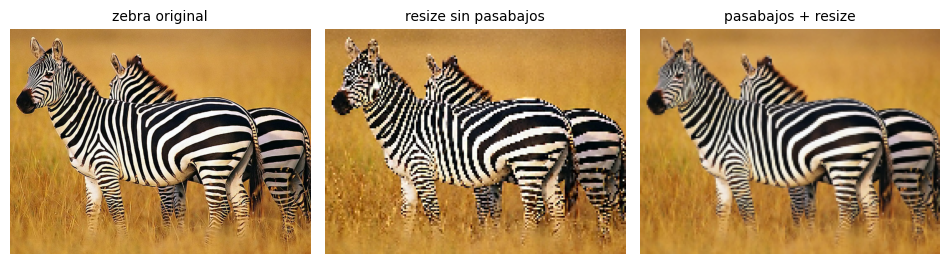

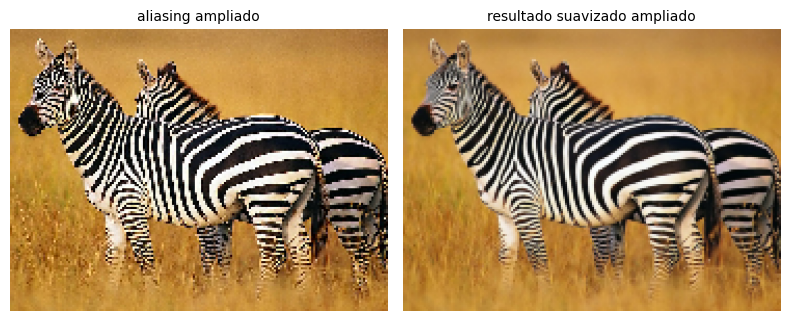

In [25]:
# Reduccion de zebra.jpg: resize sin filtro pasabajos frente a suavizado previo
zebra = cv2.imread(str(Path("zebra.jpg")))
if zebra is None:
    raise FileNotFoundError("No se encontro zebra.jpg en la carpeta del cuaderno.")

factor = 0.25
alto, ancho = zebra.shape[:2]
nuevo_tamano = (int(ancho * factor), int(alto * factor))

# INTER_NEAREST solo remuestrea: no elimina las frecuencias altas antes de reducir.
zebra_sin_filtro = cv2.resize(zebra, nuevo_tamano, interpolation=cv2.INTER_NEAREST)

# El gaussiano atenúa las frecuencias que ya no pueden representarse a menor escala.
sigma = 1.2
zebra_suavizada = cv2.GaussianBlur(zebra, (0, 0), sigmaX=sigma)
zebra_con_filtro = cv2.resize(
    zebra_suavizada, nuevo_tamano, interpolation=cv2.INTER_NEAREST
)

mostrar(
    [zebra, zebra_sin_filtro, zebra_con_filtro],
    ["zebra original", "resize sin pasabajos", "pasabajos + resize"],
    cols=3,
    escala=3.2,
)

# Ampliamos ambas reducciones para hacer visible el patron de aliasing.
mostrar(
    [
        cv2.resize(zebra_sin_filtro, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST),
        cv2.resize(zebra_con_filtro, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST),
    ],
    ["aliasing ampliado", "resultado suavizado ampliado"],
    cols=2,
    escala=4.0,
)

## 10. Resumen

| Filtro | Función OpenCV | ¿Lineal? | Preserva bordes | Uso típico |
|---|---|---|---|---|
| Promedio (box) | `blur`, `boxFilter` | sí | no | suavizado rápido, ejemplo didáctico |
| Gaussiano | `GaussianBlur` | sí | no | suavizado estándar, paso previo a bordes |
| Mediana | `medianBlur` | no | sí | ruido sal y pimienta, impulsivo |
| Bilateral | `bilateralFilter` | no | sí | reducción de ruido conservando detalle |

Ideas para retener:

- Los pesos de un kernel pasabajos deben sumar 1.
- `filter2D` calcula correlación; con kernels simétricos coincide con la
  convolución.
- El tamaño del kernel manda sobre el resto de los parámetros.
- Antes de reducir una imagen, un pasabajos evita el aliasing.
- Suavizar y perder definición son la misma operación en un filtro lineal;
  los no lineales existen para romper ese compromiso, a un costo mayor.